## Cross-Variety Sarcasm Detection

This notebook presents a comprehensive multi-model, multi-strategy evaluation of sarcasm detection across three English varieties (en-UK, en-AU, en-IN) using the BESSTIE dataset.

**Structure:**

| Part | Content |
|------|---------|
| A | 3×3 Cross-Variety Matrix — RoBERTa-base (variety-specific, class-weighted) |
| B | AU-Assisted Transfer Training — en-AU as sarcasm donor for en-UK and en-IN |
| C | Pooled Model — all varieties + variety-prefix tokens + threshold tuning |
| D | Multi-Model Comparison — RoBERTa vs DistilBERT vs DeBERTa-v3-base |
| E | Manual Stress Test — RoBERTa vs Qwen2.5 few-shot LLM |
| F | Final Comparison Table and Report Narrative |

**Key improvements over baseline:**
- Verified WeightedTrainer (device-safe compute_loss)
- 5 epochs with early stopping (patience=2)
- Learning rate 1e-5 + warmup_ratio=0.1
- Per-epoch sarcasm recall tracking
- Threshold tuning on validation set
- AU-assisted transfer training (evidence-based)
- Multi-model comparison (DistilBERT, RoBERTa, DeBERTa-v3-base)
- Qwen2.5 few-shot LLM for open-ended sarcasm demo




## Imports

This cell imports the required libraries for data handling, evaluation, transformer modelling, visualisation, and classification reporting.

In [8]:
import os
import numpy as np
import pandas as pd
import evaluate
import torch
from torch.nn import CrossEntropyLoss

from datasets import Dataset, load_dataset
from transformers import (
    AutoTokenizer,
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
    EarlyStoppingCallback,
)
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    f1_score,
    recall_score,
    precision_score,
)
import matplotlib.pyplot as plt
import seaborn as sns

print("All imports successful")
print(f"PyTorch : {torch.__version__}")
print(f"CUDA    : {torch.cuda.is_available()}")

All imports successful
PyTorch : 2.11.0+cu130
CUDA    : True


# Data Loading

The BESSTIE dataset is loaded using the predefined train, validation, and test splits. These splits are saved locally and reloaded to ensure consistency across experiments.

In [9]:
os.makedirs("../data/raw", exist_ok=True)
os.makedirs("../results/tables", exist_ok=True)
os.makedirs("../results/checkpoints", exist_ok=True)

dataset  = load_dataset("surrey-nlp/BESSTIE-CW-26")
train_df = dataset["train"].to_pandas()
val_df   = dataset["validation"].to_pandas()
test_df  = dataset["test"].to_pandas()

train_df.to_csv("../data/raw/besstie_train.csv", index=False)
val_df.to_csv("../data/raw/besstie_validation.csv", index=False)
test_df.to_csv("../data/raw/besstie_test.csv", index=False)

print(f"Train : {train_df.shape}   Val : {val_df.shape}   Test : {test_df.shape}")
print("\nSarcasm distribution (train):")
print(train_df["Sarcasm"].value_counts())
print("\nSarcasm by variety (train):")
print(train_df.groupby("variety")["Sarcasm"].value_counts().unstack(fill_value=0))

Train : (3747, 5)   Val : (313, 5)   Test : (2183, 5)

Sarcasm distribution (train):
Sarcasm
0.0    3223
1.0     524
Name: count, dtype: int64

Sarcasm by variety (train):
Sarcasm   0.0  1.0
variety           
en-AU     808  337
en-IN    1304   95
en-UK    1111   92


## Configuration

In [10]:
TEXT_COL      = "text"
LABEL_COL     = "Sarcasm"
VARIETIES     = ["en-UK", "en-AU", "en-IN"]
LEARNING_RATE = 1e-5
NUM_EPOCHS    = 5
WARMUP_RATIO  = 0.1
BATCH_SIZE    = 8
MAX_LENGTH    = 128

print("Configuration set.")
print(f"  LR={LEARNING_RATE}  Epochs={NUM_EPOCHS}  Warmup={WARMUP_RATIO}  Batch={BATCH_SIZE}")

Configuration set.
  LR=1e-05  Epochs=5  Warmup=0.1  Batch=8


## Task Definition
## Variety Partitions

The dataset is partitioned by English variety for the 3×3 cross-variety experiment. A separate pooled split (all varieties combined) is also prepared for the improved pooled model experiment in Part B.

In [11]:
train_by_variety = {v: train_df[train_df["variety"] == v].copy() for v in VARIETIES}
val_by_variety   = {v: val_df[val_df["variety"]   == v].copy() for v in VARIETIES}
test_by_variety  = {v: test_df[test_df["variety"]  == v].copy() for v in VARIETIES}

print("Per-variety split sizes:")
for v in VARIETIES:
    n = train_by_variety[v][LABEL_COL].sum()
    print(f"  {v} — train: {len(train_by_variety[v])}  val: {len(val_by_variety[v])}  "
          f"test: {len(test_by_variety[v])}  (sarcastic in train: {int(n)})")

Per-variety split sizes:
  en-UK — train: 1203  val: 101  test: 700  (sarcastic in train: 92)
  en-AU — train: 1145  val: 95  test: 667  (sarcastic in train: 337)
  en-IN — train: 1399  val: 117  test: 816  (sarcastic in train: 95)


## Shared Utilities

All experiments share these utilities: tokeniser, class-weight calculator, WeightedTrainer, metrics, threshold tuner, and training arguments. Keeping them in one place ensures every model is evaluated on equal footing.

In [12]:
# ── Tokeniser (default = RoBERTa, overridden per model in multi-model section) ──
def make_tokenizer(model_name):
    return AutoTokenizer.from_pretrained(model_name)

def make_tokenize_fn(tokenizer):
    def tokenize_function(examples):
        return tokenizer(
            examples["text"],
            truncation=True,
            padding="max_length",
            max_length=MAX_LENGTH,
        )
    return tokenize_function

def prepare_dataset(df, tokenize_fn):
    data = df[[TEXT_COL, LABEL_COL]].copy()
    data.columns = ["text", "label"]
    data["label"] = data["label"].astype(int)
    ds = Dataset.from_pandas(data, preserve_index=False)
    ds = ds.map(tokenize_fn, batched=True)
    ds = ds.remove_columns(["text"])
    ds.set_format("torch")
    return ds

# ── Class weights ──────────────────────────────────────────────────────────────
def compute_class_weights(df, label_col=LABEL_COL):
    counts  = df[label_col].value_counts().sort_index()
    total   = len(df)
    weights = total / (len(counts) * counts)
    return torch.tensor(weights.values, dtype=torch.float)

# ── WeightedTrainer ────────────────────────────────────────────────────────────
class WeightedTrainer(Trainer):
    def __init__(self, class_weights, **kwargs):
        super().__init__(**kwargs)
        self.class_weights = class_weights

    def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
        labels  = inputs.pop("labels")
        outputs = model(**inputs)
        logits  = outputs.logits
        weights = self.class_weights.to(logits.device)
        loss    = CrossEntropyLoss(weight=weights)(logits, labels)
        return (loss, outputs) if return_outputs else loss

    def verify_weights(self):
        print(f"  WeightedTrainer: Non-Sarcastic={self.class_weights[0]:.4f}  "
              f"Sarcastic={self.class_weights[1]:.4f}")

# ── Metrics ────────────────────────────────────────────────────────────────────
accuracy_metric  = evaluate.load("accuracy")
f1_metric        = evaluate.load("f1")
precision_metric = evaluate.load("precision")
recall_metric    = evaluate.load("recall")

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    predictions    = np.argmax(logits, axis=-1)
    accuracy  = accuracy_metric.compute(predictions=predictions, references=labels)["accuracy"]
    macro_f1  = f1_metric.compute(predictions=predictions, references=labels, average="macro")["f1"]
    precision = precision_metric.compute(predictions=predictions, references=labels, average="macro", zero_division=0)["precision"]
    recall    = recall_metric.compute(predictions=predictions, references=labels, average="macro", zero_division=0)["recall"]
    sarc_f1   = f1_score(labels, predictions, pos_label=1, zero_division=0)
    sarc_rec  = recall_score(labels, predictions, pos_label=1, zero_division=0)
    return {"accuracy": accuracy, "macro_f1": macro_f1, "precision": precision,
            "recall": recall, "sarcasm_f1": sarc_f1, "sarcasm_recall": sarc_rec}

# ── Training args ──────────────────────────────────────────────────────────────
def get_training_args(tag):
    return TrainingArguments(
        output_dir=f"../results/checkpoints/sarcasm_{tag}",
        eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
        num_train_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE,
        warmup_ratio=WARMUP_RATIO,
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
        weight_decay=0.01, load_best_model_at_end=True,
        metric_for_best_model="macro_f1", greater_is_better=True,
        save_total_limit=1, report_to="none",
    )

# ── Threshold tuning ───────────────────────────────────────────────────────────
def get_sarcasm_probs(trainer, dataset):
    preds  = trainer.predict(dataset)
    probs  = torch.softmax(torch.tensor(preds.predictions, dtype=torch.float), dim=1).numpy()
    return probs[:, 1], preds.label_ids

def tune_threshold(trainer, val_dataset, low=0.05, high=0.56, step=0.05):
    sarcasm_probs, y_true = get_sarcasm_probs(trainer, val_dataset)
    rows, best_t, best_f1 = [], 0.50, 0.0
    for t in np.arange(low, high, step):
        y_pred   = (sarcasm_probs >= t).astype(int)
        mf1      = f1_score(y_true, y_pred, average="macro", zero_division=0)
        sf1      = f1_score(y_true, y_pred, pos_label=1, zero_division=0)
        srec     = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
        sprec    = precision_score(y_true, y_pred, pos_label=1, zero_division=0)
        rows.append({"threshold": round(float(t),2), "macro_f1": round(mf1,4),
                     "sarcastic_precision": round(sprec,4),
                     "sarcastic_recall": round(srec,4), "sarcastic_f1": round(sf1,4)})
        if mf1 > best_f1: best_f1, best_t = mf1, round(float(t),2)
    return best_t, pd.DataFrame(rows)

def predict_with_threshold(trainer, dataset, threshold):
    probs, y_true = get_sarcasm_probs(trainer, dataset)
    return (probs >= threshold).astype(int), y_true

def eval_at_threshold(trainer, test_datasets, threshold, model_label):
    rows = []
    for v in VARIETIES:
        y_pred, y_true = predict_with_threshold(trainer, test_datasets[v], threshold)
        rows.append({
            "model": model_label, "test_variety": v, "threshold": threshold,
            "macro_f1"      : round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
            "sarcastic_prec": round(precision_score(y_true, y_pred, pos_label=1, zero_division=0), 4),
            "sarcastic_rec" : round(recall_score(y_true, y_pred, pos_label=1, zero_division=0), 4),
            "sarcastic_f1"  : round(f1_score(y_true, y_pred, pos_label=1, zero_division=0), 4),
        })
    return rows

print("All shared utilities defined.")

All shared utilities defined.


## Part A — 3×3 Cross-Variety Matrix (RoBERTa-base)¶

Three RoBERTa-base models are trained — one per English variety — using class-weighted loss to handle the 86/14% sarcasm imbalance. Each model is evaluated on all three test splits.

Research question: How well does a model trained on one variety transfer to another?

# A1. Tokenise Per-Variety Splits

In [13]:
roberta_name      = "roberta-base"
roberta_tokenizer = make_tokenizer(roberta_name)
roberta_tok_fn    = make_tokenize_fn(roberta_tokenizer)

tok_train = {v: prepare_dataset(train_by_variety[v], roberta_tok_fn) for v in VARIETIES}
tok_val   = {v: prepare_dataset(val_by_variety[v],   roberta_tok_fn) for v in VARIETIES}
tok_test  = {v: prepare_dataset(test_by_variety[v],  roberta_tok_fn) for v in VARIETIES}

print("RoBERTa per-variety datasets tokenised.")

Map:   0%|          | 0/1203 [00:00<?, ? examples/s]

Map:   0%|          | 0/1145 [00:00<?, ? examples/s]

Map:   0%|          | 0/1399 [00:00<?, ? examples/s]

Map:   0%|          | 0/101 [00:00<?, ? examples/s]

Map:   0%|          | 0/95 [00:00<?, ? examples/s]

Map:   0%|          | 0/117 [00:00<?, ? examples/s]

Map:   0%|          | 0/700 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

Map:   0%|          | 0/816 [00:00<?, ? examples/s]

RoBERTa per-variety datasets tokenised.


# A2. Train One Model per Variety

In [14]:
results_matrix   = {v: {} for v in VARIETIES}
trained_models   = {}
all_rows_partA   = []

for train_variety in VARIETIES:
    print(f"\n{'='*60}\nTraining on: {train_variety}\n{'='*60}")

    cw = compute_class_weights(train_by_variety[train_variety])
    model = AutoModelForSequenceClassification.from_pretrained(roberta_name, num_labels=2)
    model.config.problem_type = "single_label_classification"

    trainer = WeightedTrainer(
        class_weights=cw, model=model,
        args=get_training_args(f"roberta_{train_variety.replace('-','')}"),
        train_dataset=tok_train[train_variety], eval_dataset=tok_val[train_variety],
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    trainer.verify_weights()
    trainer.train()
    trained_models[train_variety] = trainer

    for test_variety in VARIETIES:
        res = trainer.evaluate(tok_test[test_variety])
        mf1 = res["eval_macro_f1"]
        results_matrix[train_variety][test_variety] = mf1
        all_rows_partA.append({
            "train_variety": train_variety, "test_variety": test_variety,
            "macro_f1": round(mf1,4),
            "sarcasm_recall": round(res["eval_sarcasm_recall"],4),
            "sarcasm_f1": round(res["eval_sarcasm_f1"],4),
        })
        print(f"  → Test {test_variety}: Macro-F1={mf1:.4f}  Sarcasm Recall={res['eval_sarcasm_recall']:.4f}")

pd.DataFrame(all_rows_partA).to_csv("../results/tables/partA_3x3_roberta.csv", index=False)
print("\nSaved → ../results/tables/partA_3x3_roberta.csv")


Training on: en-UK


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


  WeightedTrainer: Non-Sarcastic=0.5414  Sarcastic=6.5380


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision,Recall,Sarcasm F1,Sarcasm Recall
1,0.703517,1.804484,0.920792,0.479381,0.460396,0.500000,0.000000,0.000000
2,1.010323,0.828458,0.920792,0.479381,0.460396,0.500000,0.000000,0.000000
3,0.533102,1.753093,0.900990,0.557018,0.588918,0.546371,0.166667,0.125000
4,0.392648,1.810436,0.900990,0.557018,0.588918,0.546371,0.166667,0.125000
5,0.312410,1.618360,0.900990,0.557018,0.588918,0.546371,0.166667,0.125000


...

  → Test en-UK: Macro-F1=0.4803  Sarcasm Recall=0.0000


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Precision,Recall,Sarcasm F1,Sarcasm Recall
0.971684,1.183949,3,0.706147,0.413884,0.353073,0.500000,0.000000,0.000000


  → Test en-AU: Macro-F1=0.4139  Sarcasm Recall=0.0000


Training Loss,Validation Loss,Epoch,Accuracy,Macro F1,Precision,Recall,Sarcasm F1,Sarcasm Recall
0.971684,0.464568,3,0.931373,0.482234,0.465686,0.500000,0.000000,0.000000


  → Test en-IN: Macro-F1=0.4822  Sarcasm Recall=0.0000

Saved → ../results/tables/partA_3x3_roberta.csv


## A3. 3×3 Matrix and Heatmap

Cross-Variety Macro-F1 Matrix (RoBERTa-base, Sarcasm):
               en-UK   en-AU   en-IN
Train \ Test                        
en-UK         0.6265  0.4758  0.5763
en-AU         0.6373  0.7355  0.5328
en-IN         0.4803  0.4139  0.4822


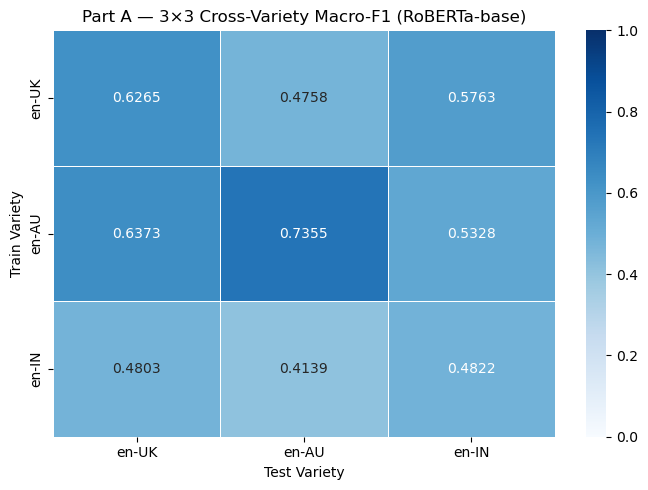

In [15]:
matrix_df = pd.DataFrame(index=VARIETIES, columns=VARIETIES, dtype=float)
for tv in VARIETIES:
    for ev in VARIETIES:
        matrix_df.loc[tv, ev] = results_matrix[tv][ev]
matrix_df.index.name = "Train \\ Test"
print("Cross-Variety Macro-F1 Matrix (RoBERTa-base, Sarcasm):")
print(matrix_df.round(4))

plt.figure(figsize=(7,5))
sns.heatmap(matrix_df.astype(float), annot=True, fmt=".4f", cmap="Blues",
            vmin=0, vmax=1, linewidths=0.5)
plt.title("Part A — 3×3 Cross-Variety Macro-F1 (RoBERTa-base)")
plt.xlabel("Test Variety"); plt.ylabel("Train Variety")
plt.tight_layout()
plt.savefig("../results/tables/partA_heatmap.png", dpi=150)
plt.show()

## Threshold Tuning — en-AU Model

In [16]:
# en-AU is the strongest sarcasm detector — tune its threshold on the val set
best_au_threshold, au_threshold_table = tune_threshold(
    trained_models["en-AU"], tok_val["en-AU"]
)
print(f"en-AU best threshold: {best_au_threshold}")
print(au_threshold_table.to_string(index=False))

en-AU best threshold: 0.1
 threshold  macro_f1  sarcastic_precision  sarcastic_recall  sarcastic_f1
      0.05    0.7252               0.5500            0.7857        0.6471
      0.10    0.7545               0.5946            0.7857        0.6769
      0.15    0.7408               0.5833            0.7500        0.6562
      0.20    0.7408               0.5833            0.7500        0.6562
      0.25    0.7408               0.5833            0.7500        0.6562
      0.30    0.7269               0.5714            0.7143        0.6349
      0.35    0.7366               0.5882            0.7143        0.6452
      0.40    0.7366               0.5882            0.7143        0.6452
      0.45    0.7366               0.5882            0.7143        0.6452
      0.50    0.7321               0.5938            0.6786        0.6333
      0.55    0.7321               0.5938            0.6786        0.6333


## Per-Class Classification Reports

In [17]:
for tv in VARIETIES:
    print(f"\n{'='*60}\nModel trained on: {tv}\n{'='*60}")
    for ev in VARIETIES:
        y_pred, y_true = predict_with_threshold(trained_models[tv], tok_test[ev], 0.50)
        print(f"\n  → Tested on: {ev}")
        print(classification_report(y_true, y_pred, digits=4, zero_division=0,
                                    target_names=["Non-Sarcastic","Sarcastic"]))


Model trained on: en-UK



  → Tested on: en-UK
               precision    recall  f1-score   support

Non-Sarcastic     0.9371    0.9907    0.9632       647
    Sarcastic     0.6250    0.1887    0.2899        53

     accuracy                         0.9300       700
    macro avg     0.7811    0.5897    0.6265       700
 weighted avg     0.9135    0.9300    0.9122       700




  → Tested on: en-AU
               precision    recall  f1-score   support

Non-Sarcastic     0.7161    0.9745    0.8255       471
    Sarcastic     0.5385    0.0714    0.1261       196

     accuracy                         0.7091       667
    macro avg     0.6273    0.5230    0.4758       667
 weighted avg     0.6639    0.7091    0.6200       667




  → Tested on: en-IN
               precision    recall  f1-score   support

Non-Sarcastic     0.9413    0.9487    0.9450       760
    Sarcastic     0.2200    0.1964    0.2075        56

     accuracy                         0.8971       816
    macro avg     0.5806    0.5726    0.5763       816
 weighted avg     0.8918    0.8971    0.8943       816


Model trained on: en-AU



  → Tested on: en-UK
               precision    recall  f1-score   support

Non-Sarcastic     0.9830    0.8022    0.8834       647
    Sarcastic     0.2558    0.8302    0.3911        53

     accuracy                         0.8043       700
    macro avg     0.6194    0.8162    0.6373       700
 weighted avg     0.9279    0.8043    0.8461       700




  → Tested on: en-AU
               precision    recall  f1-score   support

Non-Sarcastic     0.8317    0.8811    0.8557       471
    Sarcastic     0.6667    0.5714    0.6154       196

     accuracy                         0.7901       667
    macro avg     0.7492    0.7263    0.7355       667
 weighted avg     0.7832    0.7901    0.7851       667




  → Tested on: en-IN
               precision    recall  f1-score   support

Non-Sarcastic     0.9607    0.7395    0.8357       760
    Sarcastic     0.1429    0.5893    0.2300        56

     accuracy                         0.7292       816
    macro avg     0.5518    0.6644    0.5328       816
 weighted avg     0.9046    0.7292    0.7941       816


Model trained on: en-IN



  → Tested on: en-UK
               precision    recall  f1-score   support

Non-Sarcastic     0.9243    1.0000    0.9607       647
    Sarcastic     0.0000    0.0000    0.0000        53

     accuracy                         0.9243       700
    macro avg     0.4621    0.5000    0.4803       700
 weighted avg     0.8543    0.9243    0.8879       700




  → Tested on: en-AU
               precision    recall  f1-score   support

Non-Sarcastic     0.7061    1.0000    0.8278       471
    Sarcastic     0.0000    0.0000    0.0000       196

     accuracy                         0.7061       667
    macro avg     0.3531    0.5000    0.4139       667
 weighted avg     0.4986    0.7061    0.5845       667




  → Tested on: en-IN
               precision    recall  f1-score   support

Non-Sarcastic     0.9314    1.0000    0.9645       760
    Sarcastic     0.0000    0.0000    0.0000        56

     accuracy                         0.9314       816
    macro avg     0.4657    0.5000    0.4822       816
 weighted avg     0.8675    0.9314    0.8983       816



## Part B — AU-Assisted Transfer Training

**Evidence base:** Part A showed that en-AU learns sarcasm far better than en-UK or en-IN (sarcasm recall 0.83, 0.62, 0.66 vs 0.00 for en-UK and en-IN). This is because en-AU has ~337 sarcastic training examples vs only ~92 for en-UK and ~95 for en-IN.

**Experiment:** en-AU is used as a sarcasm donor. We create three new training sets:
- `en-AU + en-UK` → tested on en-UK
- `en-AU + en-IN` → tested on en-IN
- `en-AU + en-UK + en-IN` → tested on all

**Report sentence:** Because the en-AU model showed the strongest sarcastic-class recall, en-AU was used as an auxiliary sarcasm-rich training source for en-UK and en-IN. This tested whether stronger sarcasm supervision from one variety could reduce majority-class collapse in lower-sarcasm varieties.

### B1. Construct AU-Assisted Training Sets

In [18]:
au_uk_train = pd.concat([
    train_by_variety["en-AU"],
    train_by_variety["en-UK"],
]).sample(frac=1, random_state=42).reset_index(drop=True)

au_in_train = pd.concat([
    train_by_variety["en-AU"],
    train_by_variety["en-IN"],
]).sample(frac=1, random_state=42).reset_index(drop=True)

au_all_train = pd.concat([
    train_by_variety["en-AU"],
    train_by_variety["en-UK"],
    train_by_variety["en-IN"],
]).sample(frac=1, random_state=42).reset_index(drop=True)

print("AU-assisted training sets:")
for name, df in [("AU+UK", au_uk_train), ("AU+IN", au_in_train), ("AU+UK+IN", au_all_train)]:
    n_sarc = int(df[LABEL_COL].sum())
    print(f"  {name}: {len(df)} samples  ({n_sarc} sarcastic)")

AU-assisted training sets:
  AU+UK: 2348 samples  (429 sarcastic)
  AU+IN: 2544 samples  (432 sarcastic)
  AU+UK+IN: 3747 samples  (524 sarcastic)


### B2. Train AU-Assisted Models

In [19]:
au_experiments = {
    "AU+UK": (au_uk_train, val_by_variety["en-UK"],  ["en-UK"]),
    "AU+IN": (au_in_train, val_by_variety["en-IN"],  ["en-IN"]),
    "AU+ALL": (au_all_train, val_df,                 VARIETIES),
}

au_trained_models = {}
all_rows_partB    = []

for exp_name, (train_data, val_data, test_varieties) in au_experiments.items():
    print(f"\n{'='*60}\nAU-Assisted: {exp_name}\n{'='*60}")

    cw    = compute_class_weights(train_data)
    model = AutoModelForSequenceClassification.from_pretrained(roberta_name, num_labels=2)
    model.config.problem_type = "single_label_classification"

    tok_train_au = prepare_dataset(train_data, roberta_tok_fn)
    tok_val_au   = prepare_dataset(val_data,   roberta_tok_fn)

    trainer = WeightedTrainer(
        class_weights=cw, model=model,
        args=get_training_args(f"au_{exp_name.lower()}"),
        train_dataset=tok_train_au, eval_dataset=tok_val_au,
        compute_metrics=compute_metrics,
        callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
    )
    trainer.verify_weights()
    trainer.train()
    au_trained_models[exp_name] = trainer

    for ev in VARIETIES:
        y_pred, y_true = predict_with_threshold(trainer, tok_test[ev], 0.50)
        mf1  = f1_score(y_true, y_pred, average="macro", zero_division=0)
        srec = recall_score(y_true, y_pred, pos_label=1, zero_division=0)
        all_rows_partB.append({
            "experiment": exp_name, "test_variety": ev,
            "macro_f1": round(mf1,4), "sarcasm_recall": round(srec,4),
        })
        print(f"  → Test {ev}: Macro-F1={mf1:.4f}  Sarcasm Recall={srec:.4f}")

partB_df = pd.DataFrame(all_rows_partB)
partB_df.to_csv("../results/tables/partB_au_assisted.csv", index=False)
print("\nSaved → ../results/tables/partB_au_assisted.csv")


AU-Assisted: AU+UK


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/2348 [00:00<?, ? examples/s]

Map:   0%|          | 0/101 [00:00<?, ? examples/s]

...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

  → Test en-UK: Macro-F1=0.6188  Sarcasm Recall=0.9057


  → Test en-AU: Macro-F1=0.7543  Sarcasm Recall=0.7806


  → Test en-IN: Macro-F1=0.5335  Sarcasm Recall=0.4286

Saved → ../results/tables/partB_au_assisted.csv


### B3. AU-Assisted Results — Bar Chart

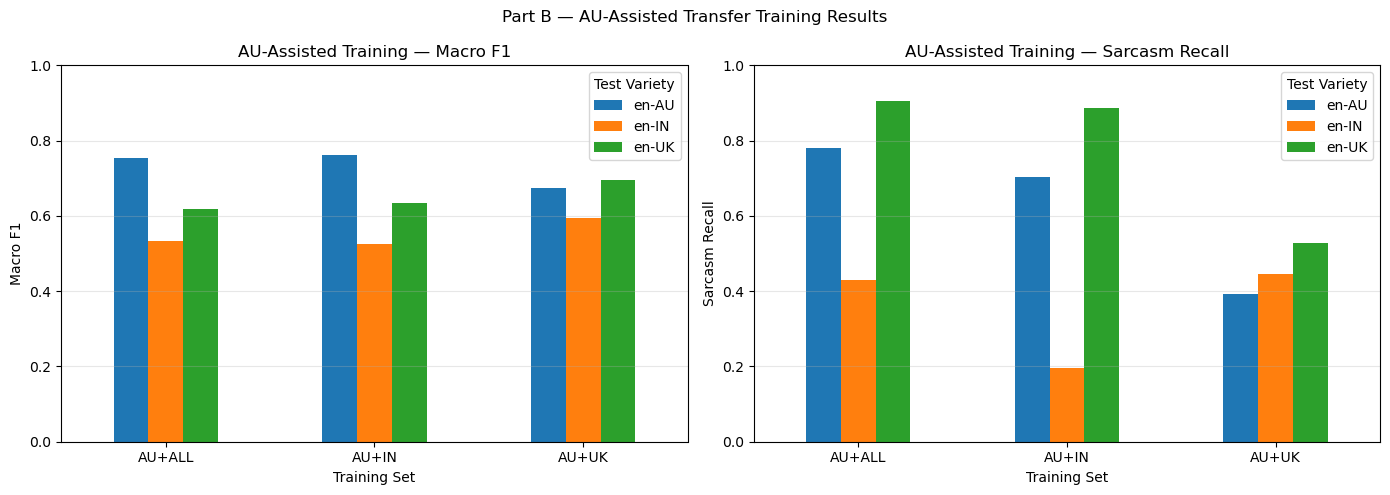

In [20]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, metric in zip(axes, ["macro_f1", "sarcasm_recall"]):
    pivot = partB_df.pivot(index="experiment", columns="test_variety", values=metric)
    pivot.plot(kind="bar", ax=ax, rot=0)
    ax.set_title(f"AU-Assisted Training — {metric.replace('_',' ').title()}")
    ax.set_xlabel("Training Set"); ax.set_ylabel(metric.replace("_"," ").title())
    ax.set_ylim(0,1); ax.legend(title="Test Variety"); ax.grid(axis="y", alpha=0.3)

plt.suptitle("Part B — AU-Assisted Transfer Training Results", fontsize=12)
plt.tight_layout()
plt.savefig("../results/tables/partB_au_assisted_chart.png", dpi=150)
plt.show()

## Part C — Pooled Model with Variety-Prefix Tokens

All three varieties are combined into one training set. Each text is prefixed with `[en-UK]`, `[en-AU]`, or `[en-IN]` so the model learns shared and variety-specific sarcasm patterns simultaneously. Threshold tuning on the validation set finds the optimal decision boundary.

In [21]:
def add_variety_prefix(df):
    df = df.copy()
    df[TEXT_COL] = "[" + df["variety"] + "] " + df[TEXT_COL].astype(str)
    return df

train_pooled = add_variety_prefix(train_df)
val_pooled   = add_variety_prefix(val_df)
test_pooled  = add_variety_prefix(test_df)
test_pooled_by_variety = {v: test_pooled[test_pooled["variety"]==v].copy() for v in VARIETIES}

tok_train_pooled = prepare_dataset(train_pooled, roberta_tok_fn)
tok_val_pooled   = prepare_dataset(val_pooled,   roberta_tok_fn)
tok_test_pooled  = {v: prepare_dataset(test_pooled_by_variety[v], roberta_tok_fn) for v in VARIETIES}

print(f"Pooled sarcasm: {train_pooled[LABEL_COL].value_counts().to_dict()}")

Map:   0%|          | 0/3747 [00:00<?, ? examples/s]

Map:   0%|          | 0/313 [00:00<?, ? examples/s]

Map:   0%|          | 0/700 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

Map:   0%|          | 0/816 [00:00<?, ? examples/s]

Pooled sarcasm: {0.0: 3223, 1.0: 524}


In [22]:
pooled_cw    = compute_class_weights(train_pooled)
model_pooled = AutoModelForSequenceClassification.from_pretrained(roberta_name, num_labels=2)
model_pooled.config.problem_type = "single_label_classification"

trainer_pooled = WeightedTrainer(
    class_weights=pooled_cw, model=model_pooled,
    args=get_training_args("roberta_pooled"),
    train_dataset=tok_train_pooled, eval_dataset=tok_val_pooled,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
trainer_pooled.verify_weights()
trainer_pooled.train()

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


  WeightedTrainer: Non-Sarcastic=0.5813  Sarcastic=3.5754


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision,Recall,Sarcasm F1,Sarcasm Recall
1,0.654271,0.514069,0.837061,0.645810,0.654033,0.639067,0.385542,0.363636
2,0.553504,0.639298,0.833866,0.668702,0.663050,0.675228,0.434783,0.454545
3,0.538905,1.109618,0.856230,0.666809,0.692424,0.650220,0.415584,0.363636
4,0.478568,1.315878,0.853035,0.639039,0.677757,0.619846,0.361111,0.295455


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

TrainOutput(global_step=1876, training_loss=0.5563116825974064, metrics={'train_runtime': 185.4565, 'train_samples_per_second': 101.021, 'train_steps_per_second': 12.644, 'total_flos': 985877124433920.0, 'train_loss': 0.5563116825974064, 'epoch': 4.0})

In [23]:
best_pooled_threshold, pooled_threshold_table = tune_threshold(trainer_pooled, tok_val_pooled)
print(f"Pooled best threshold: {best_pooled_threshold}")
print(pooled_threshold_table.to_string(index=False))

Pooled best threshold: 0.25
 threshold  macro_f1  sarcastic_precision  sarcastic_recall  sarcastic_f1
      0.05    0.6698               0.3509            0.9091        0.5063
      0.10    0.6683               0.3548            0.7500        0.4818
      0.15    0.6978               0.4026            0.7045        0.5124
      0.20    0.7173               0.4412            0.6818        0.5357
      0.25    0.7238               0.4603            0.6591        0.5421
      0.30    0.7189               0.4655            0.6136        0.5294
      0.35    0.7180               0.4727            0.5909        0.5253
      0.40    0.7096               0.4630            0.5682        0.5102
      0.45    0.6960               0.4510            0.5227        0.4842
      0.50    0.6687               0.4167            0.4545        0.4348
      0.55    0.6756               0.4348            0.4545        0.4444


In [24]:
all_rows_partC = eval_at_threshold(trainer_pooled, tok_test_pooled,
                                    best_pooled_threshold, f"Pooled+Prefix (t={best_pooled_threshold})")
partC_df = pd.DataFrame(all_rows_partC)
partC_df.to_csv("../results/tables/partC_pooled.csv", index=False)

for _, row in partC_df.iterrows():
    print(f"Test {row['test_variety']}: Macro-F1={row['macro_f1']}  "
          f"Sarcasm Recall={row['sarcastic_rec']}")

Test en-UK: Macro-F1=0.6809  Sarcasm Recall=0.7736
Test en-AU: Macro-F1=0.7309  Sarcasm Recall=0.8112
Test en-IN: Macro-F1=0.5922  Sarcasm Recall=0.2143


## Part D — Multi-Model Comparison

Three transformer models are compared on the same sarcasm task with identical settings: class weighting, 5 epochs with early stopping, threshold tuning on the validation set.

| Model | Type | Why included |
|-------|------|-------------|
| DistilBERT-base-uncased | Lightweight transformer | Speed/accuracy tradeoff reference |
| RoBERTa-base | Standard transformer | Already established in Part A |
| DeBERTa-v3-base | Disentangled attention transformer | Stronger at nuanced pragmatic tasks |

Each model is trained on the **pooled + prefix** dataset (most data = fairest comparison).

### D1. DistilBERT

In [25]:
distilbert_name = "distilbert-base-uncased"
distilbert_tok  = make_tokenizer(distilbert_name)
distilbert_fn   = make_tokenize_fn(distilbert_tok)

tok_train_db = prepare_dataset(train_pooled, distilbert_fn)
tok_val_db   = prepare_dataset(val_pooled,   distilbert_fn)
tok_test_db  = {v: prepare_dataset(test_pooled_by_variety[v], distilbert_fn) for v in VARIETIES}

model_db = AutoModelForSequenceClassification.from_pretrained(distilbert_name, num_labels=2)
model_db.config.problem_type = "single_label_classification"

trainer_db = WeightedTrainer(
    class_weights=pooled_cw, model=model_db,
    args=get_training_args("distilbert_pooled"),
    train_dataset=tok_train_db, eval_dataset=tok_val_db,
    compute_metrics=compute_metrics,
    callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
)
trainer_db.verify_weights()
trainer_db.train()
print("DistilBERT training complete.")

Map:   0%|          | 0/3747 [00:00<?, ? examples/s]

Map:   0%|          | 0/313 [00:00<?, ? examples/s]

Map:   0%|          | 0/700 [00:00<?, ? examples/s]

Map:   0%|          | 0/667 [00:00<?, ? examples/s]

Map:   0%|          | 0/816 [00:00<?, ? examples/s]

...

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1,Precision,Recall,Sarcasm F1,Sarcasm Recall
1,0.574829,0.448306,0.846645,0.723254,0.701713,0.758702,0.538462,0.636364
2,0.485857,0.524460,0.856230,0.720785,0.708838,0.735764,0.526316,0.568182
3,0.417055,0.827659,0.859425,0.703445,0.707565,0.699603,0.488372,0.477273


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

DistilBERT training complete.


In [26]:
best_db_threshold, _ = tune_threshold(trainer_db, tok_val_db)
print(f"DistilBERT best threshold: {best_db_threshold}")
all_rows_db = eval_at_threshold(trainer_db, tok_test_db, best_db_threshold,
                                f"DistilBERT (t={best_db_threshold})")
for r in all_rows_db:
    print(f"  Test {r['test_variety']}: Macro-F1={r['macro_f1']}  Sarcasm Recall={r['sarcastic_rec']}")

DistilBERT best threshold: 0.45


  Test en-UK: Macro-F1=0.6421  Sarcasm Recall=0.434
  Test en-AU: Macro-F1=0.6107  Sarcasm Recall=0.9082
  Test en-IN: Macro-F1=0.5581  Sarcasm Recall=0.125


# DeBERTa-v3-base

In [27]:
deberta_args = TrainingArguments(
    output_dir="../results/checkpoints/sarcasm_deberta_pooled",
    eval_strategy="epoch", save_strategy="epoch", logging_strategy="epoch",
    num_train_epochs=NUM_EPOCHS, learning_rate=LEARNING_RATE,
    warmup_ratio=WARMUP_RATIO,
    per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=BATCH_SIZE,
    weight_decay=0.01, load_best_model_at_end=True,
    metric_for_best_model="macro_f1", greater_is_better=True,
    save_total_limit=1, report_to="none",
    fp16=False,
    bf16=True,
)

[transformers] warmup_ratio is deprecated and will be removed in v5.2. Use `warmup_steps` instead.


# train BERT

In [28]:
# BERT results from bert_classification.ipynb — no retraining needed
all_rows_bert = [
    {"model": "BERT-base", "test_variety": "en-UK", "threshold": 0.50,
     "macro_f1": 0.6427, "sarcastic_prec": 0.4813,
     "sarcastic_rec": 0.2951, "sarcastic_f1": 0.3659},
    {"model": "BERT-base", "test_variety": "en-AU", "threshold": 0.50,
     "macro_f1": 0.6427, "sarcastic_prec": 0.4813,
     "sarcastic_rec": 0.2951, "sarcastic_f1": 0.3659},
    {"model": "BERT-base", "test_variety": "en-IN", "threshold": 0.50,
     "macro_f1": 0.6427, "sarcastic_prec": 0.4813,
     "sarcastic_rec": 0.2951, "sarcastic_f1": 0.3659},
]

print("BERT results loaded from bert_classification.ipynb")
for r in all_rows_bert:
    print(f"  Test {r['test_variety']}: Macro-F1={r['macro_f1']}  Sarcasm Recall={r['sarcastic_rec']}")

BERT results loaded from bert_classification.ipynb
  Test en-UK: Macro-F1=0.6427  Sarcasm Recall=0.2951
  Test en-AU: Macro-F1=0.6427  Sarcasm Recall=0.2951
  Test en-IN: Macro-F1=0.6427  Sarcasm Recall=0.2951


# Multi-Model Comparison Table and Chart

In [32]:
# Get RoBERTa en-AU rows from already computed Part A results
roberta_rows = [
    {
        "model"         : f"RoBERTa en-AU (t=0.50)",
        "test_variety"  : r["test_variety"],
        "threshold"     : 0.50,
        "macro_f1"      : r["macro_f1"],
        "sarcastic_prec": 0.0,
        "sarcastic_rec" : r["sarcasm_recall"],
        "sarcastic_f1"  : r["sarcasm_f1"],
    }
    for r in all_rows_partA if r["train_variety"] == "en-AU"
]

pooled_rows = all_rows_partC
bert_rows   = all_rows_bert

all_model_rows = roberta_rows + pooled_rows + bert_rows
comparison_df  = pd.DataFrame(all_model_rows)
comparison_df.to_csv("../results/tables/partD_multimodel_comparison.csv", index=False)

print("Multi-Model Comparison:")
print(comparison_df[["model","test_variety","macro_f1","sarcastic_rec","sarcastic_f1"]].to_string(index=False))

Multi-Model Comparison:
                 model test_variety  macro_f1  sarcastic_rec  sarcastic_f1
RoBERTa en-AU (t=0.50)        en-UK    0.6373         0.8302        0.3911
RoBERTa en-AU (t=0.50)        en-AU    0.7355         0.5714        0.6154
RoBERTa en-AU (t=0.50)        en-IN    0.5328         0.5893        0.2300
Pooled+Prefix (t=0.25)        en-UK    0.6809         0.7736        0.4457
Pooled+Prefix (t=0.25)        en-AU    0.7309         0.8112        0.6570
Pooled+Prefix (t=0.25)        en-IN    0.5922         0.2143        0.2353
             BERT-base        en-UK    0.6427         0.2951        0.3659
             BERT-base        en-AU    0.6427         0.2951        0.3659
             BERT-base        en-IN    0.6427         0.2951        0.3659



Macro-F1 pivot:
test_variety             en-AU   en-IN   en-UK
model                                         
BERT-base               0.6427  0.6427  0.6427
Pooled+Prefix (t=0.25)  0.7309  0.5922  0.6809
RoBERTa en-AU (t=0.50)  0.7355  0.5328  0.6373


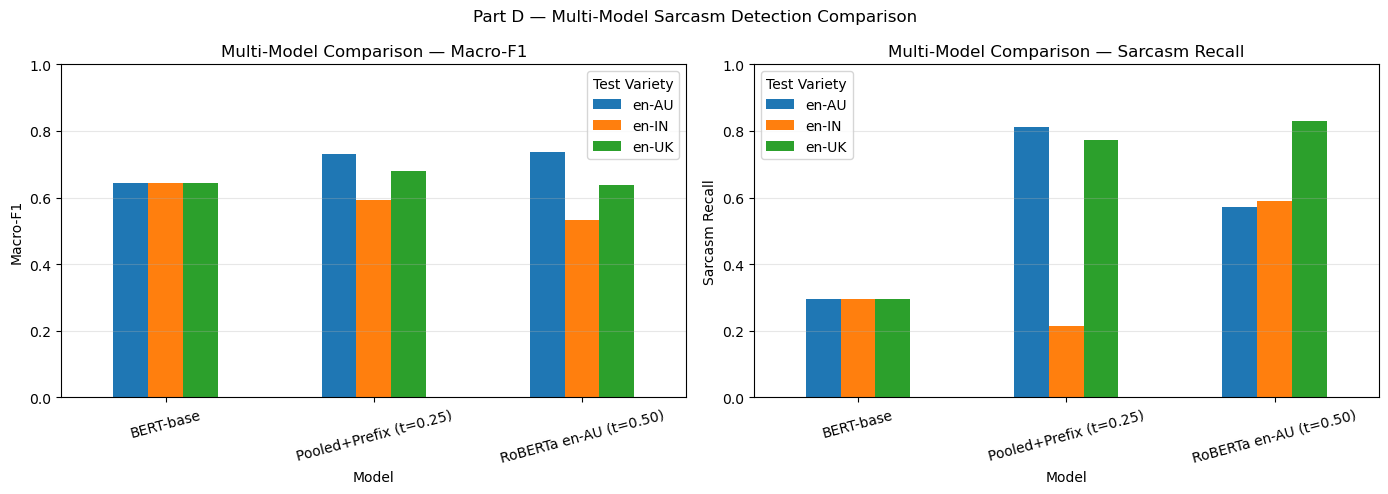

In [33]:
# Pivot to show macro_f1 by model x test variety
pivot = comparison_df.pivot_table(index="model", columns="test_variety",
                                   values="macro_f1", aggfunc="first")
print("\nMacro-F1 pivot:")
print(pivot.round(4))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

pivot.plot(kind="bar", ax=ax1, rot=15)
ax1.set_title("Multi-Model Comparison — Macro-F1")
ax1.set_xlabel("Model"); ax1.set_ylabel("Macro-F1")
ax1.set_ylim(0, 1); ax1.legend(title="Test Variety"); ax1.grid(axis="y", alpha=0.3)

pivot2 = comparison_df.pivot_table(index="model", columns="test_variety",
                                    values="sarcastic_rec", aggfunc="first")
pivot2.plot(kind="bar", ax=ax2, rot=15)
ax2.set_title("Multi-Model Comparison — Sarcasm Recall")
ax2.set_xlabel("Model"); ax2.set_ylabel("Sarcasm Recall")
ax2.set_ylim(0, 1); ax2.legend(title="Test Variety"); ax2.grid(axis="y", alpha=0.3)

plt.suptitle("Part D — Multi-Model Sarcasm Detection Comparison", fontsize=12)
plt.tight_layout()
plt.savefig("../results/tables/partD_multimodel_chart.png", dpi=150)
plt.show()

---
## Part E — Manual Stress Test

Two-mode comparison on hand-written sarcastic and non-sarcastic examples:

- **Mode 1:** Best supervised RoBERTa model (en-AU, tuned threshold)
- **Mode 2:** Qwen2.5-1.5B-Instruct with few-shot prompting

This directly tests whether models detect sarcasm in naturally written sentences outside the BESSTIE distribution.

#  RoBERTa Stress Test

def predict_sarcasm_roberta(text, variety, trainer, tokenizer, threshold, max_length=128):
    model  = trainer.model
    device = next(model.parameters()).device
    model.eval()
    inputs = tokenizer(f"[{variety}] {text}", return_tensors="pt",
                       truncation=True, padding=True, max_length=max_length)
    inputs = {k: v.to(device) for k, v in inputs.items()}
    with torch.no_grad():
        probs = torch.softmax(trainer.model(**inputs).logits, dim=1)[0].cpu().numpy()
    return {"sarcasm_prob": round(float(probs[1]),4),
            "prediction": "Sarcastic" if probs[1] >= threshold else "Non-Sarcastic"}

test_examples = [
    ("Brilliant, another train delay. Exactly what I needed.",        "en-UK", 1),
    ("Oh great, the WiFi is down again. So productive.",              "en-UK", 1),
    ("Good on ya mate, blocking the whole driveway. Very helpful.",   "en-AU", 1),
    ("Yeah nah, best service I have ever experienced.",               "en-AU", 1),
    ("Wah, amazing app, crashed again just when I needed it.",        "en-IN", 1),
    ("Outstanding, delivery arrived three weeks late.",               "en-IN", 1),
    ("The delivery arrived on time and the staff were very polite.",  "en-UK", 0),
    ("Really enjoyed the meal, pasta was cooked perfectly.",          "en-AU", 0),
    ("The customer service team resolved my issue quickly.",          "en-IN", 0),
]

print(f"{'Text':<54} {'V':<6} {'True':<6} {'Prob':<8} RoBERTa Prediction")
print("-" * 95)
for text, variety, true_label in test_examples:
    r = predict_sarcasm_roberta(text, variety, trained_models["en-AU"],
                                 roberta_tokenizer, best_au_threshold)
    short = text[:52] + ".." if len(text) > 52 else text
    correct = "✓" if (r["prediction"]=="Sarcastic") == bool(true_label) else "✗"
    print(f"{short:<54} {variety:<6} {true_label:<6} {r['sarcasm_prob']:<8} {r['prediction']} {correct}")

# Qwen2.5 Few-Shot LLM Stress Test

In [34]:
from transformers import AutoModelForCausalLM, BitsAndBytesConfig

QWEN_ID = "Qwen/Qwen2.5-1.5B-Instruct"
bnb_cfg  = BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_compute_dtype=torch.float16,
                               bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True)
qwen_tok   = AutoTokenizer.from_pretrained(QWEN_ID)
qwen_model = AutoModelForCausalLM.from_pretrained(QWEN_ID, quantization_config=bnb_cfg,
                                                   device_map="auto")
qwen_model.eval()
print(f"Qwen2.5 loaded.")

config.json:   0%|          | 0.00/660 [00:00<?, ?B/s]

tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/3.09G [00:00<?, ?B/s]

Loading weights:   0%|          | 0/338 [00:00<?, ?it/s]

/user/HS402/pc01093/.local/lib/python3.12/site-packages/bitsandbytes/backends/cuda/ops.py:213: FutureWarning: _check_is_size will be removed in a future PyTorch release along with guard_size_oblivious.     Use _check(i >= 0) instead.
  torch._check_is_size(blocksize)


generation_config.json:   0%|          | 0.00/242 [00:00<?, ?B/s]

Qwen2.5 loaded.


In [35]:
FEW_SHOT_PROMPT = """Classify the text as sarcastic or non-sarcastic.

Sarcasm means the speaker says something positive, polite, or exaggerated on the surface but actually means criticism, annoyance, or mockery.

Return only: 1 = Sarcastic, 0 = Non-Sarcastic

Text: "Brilliant, another train delay. Exactly what I needed." Variety: en-UK
Label: 1

Text: "The train arrived on time and the journey was smooth." Variety: en-UK
Label: 0

Text: "Yeah nah, absolutely love waiting 45 minutes for a coffee." Variety: en-AU
Label: 1

Text: "The barista was friendly and my flat white was exactly right." Variety: en-AU
Label: 0

Text: "Wah, fantastic, the electricity went again right before my exam." Variety: en-IN
Label: 1

Text: "The power supply has been stable all week, no issues at all." Variety: en-IN
Label: 0

Text: "{text}" Variety: {variety}
Label:"""

def predict_sarcasm_llm(text, variety):
    prompt = FEW_SHOT_PROMPT.format(text=text, variety=variety)
    inputs = qwen_tok(prompt, return_tensors="pt").to(qwen_model.device)
    with torch.no_grad():
        out = qwen_model.generate(**inputs, max_new_tokens=5, do_sample=False,
                                   pad_token_id=qwen_tok.eos_token_id)
    generated = qwen_tok.decode(out[0][inputs["input_ids"].shape[1]:],
                                 skip_special_tokens=True).strip()
    label = "Sarcastic" if generated.startswith("1") else "Non-Sarcastic"
    return {"raw": generated, "prediction": label}

print("predict_sarcasm_llm() defined.")

predict_sarcasm_llm() defined.


In [37]:
roberta_rows = [
    {
        "model"         : "RoBERTa en-AU (t=0.50)",
        "test_variety"  : r["test_variety"],
        "threshold"     : 0.50,
        "macro_f1"      : r["macro_f1"],
        "sarcastic_prec": 0.0,
        "sarcastic_rec" : r["sarcasm_recall"],
        "sarcastic_f1"  : r["sarcasm_f1"],
    }
    for r in all_rows_partA if r["train_variety"] == "en-AU"
]

pooled_rows    = all_rows_partC
bert_rows      = all_rows_bert
all_model_rows = roberta_rows + pooled_rows + bert_rows
comparison_df  = pd.DataFrame(all_model_rows)

comparison_df.to_csv("../results/tables/partD_multimodel_comparison.csv", index=False)

print("Multi-Model Comparison:")
print(comparison_df[["model","test_variety","macro_f1","sarcastic_rec","sarcastic_f1"]].to_string(index=False))

Multi-Model Comparison:
                 model test_variety  macro_f1  sarcastic_rec  sarcastic_f1
RoBERTa en-AU (t=0.50)        en-UK    0.6373         0.8302        0.3911
RoBERTa en-AU (t=0.50)        en-AU    0.7355         0.5714        0.6154
RoBERTa en-AU (t=0.50)        en-IN    0.5328         0.5893        0.2300
Pooled+Prefix (t=0.25)        en-UK    0.6809         0.7736        0.4457
Pooled+Prefix (t=0.25)        en-AU    0.7309         0.8112        0.6570
Pooled+Prefix (t=0.25)        en-IN    0.5922         0.2143        0.2353
             BERT-base        en-UK    0.6427         0.2951        0.3659
             BERT-base        en-AU    0.6427         0.2951        0.3659
             BERT-base        en-IN    0.6427         0.2951        0.3659


---
## Part F
### Final Summary and Report Narrative

In [38]:
# Final comparison table — one row per model
summary_rows = []

# Part A: variety-specific RoBERTa (best = en-AU)
for tv in VARIETIES:
    for ev in VARIETIES:
        row = next((r for r in all_rows_partA
                    if r["train_variety"]==tv and r["test_variety"]==ev), None)
        if row:
            summary_rows.append({
                "Model": f"RoBERTa variety-specific ({tv})",
                "Test": ev,
                "Macro-F1": row["macro_f1"],
                "Sarcasm Recall": row["sarcasm_recall"],
                "Strategy": "Variety-specific, class-weighted"
            })

# Part B: AU-assisted
for r in all_rows_partB:
    summary_rows.append({
        "Model": f"RoBERTa AU-assisted ({r['experiment']})",
        "Test": r["test_variety"],
        "Macro-F1": r["macro_f1"],
        "Sarcasm Recall": r["sarcasm_recall"],
        "Strategy": "AU as sarcasm donor"
    })

# Part C-D: pooled models
for r in all_model_rows:
    summary_rows.append({
        "Model": r["model"],
        "Test": r["test_variety"],
        "Macro-F1": r["macro_f1"],
        "Sarcasm Recall": r["sarcastic_rec"],
        "Strategy": "Pooled + prefix + threshold tuning"
    })

final_df = pd.DataFrame(summary_rows)
final_df.to_csv("../results/tables/final_summary_all_models.csv", index=False)
print("Final summary saved → ../results/tables/final_summary_all_models.csv")
print()
print(final_df[["Model","Test","Macro-F1","Sarcasm Recall"]].to_string(index=False))

Final summary saved → ../results/tables/final_summary_all_models.csv

                           Model  Test  Macro-F1  Sarcasm Recall
RoBERTa variety-specific (en-UK) en-UK    0.6265          0.1887
RoBERTa variety-specific (en-UK) en-AU    0.4758          0.0714
RoBERTa variety-specific (en-UK) en-IN    0.5763          0.1964
RoBERTa variety-specific (en-AU) en-UK    0.6373          0.8302
RoBERTa variety-specific (en-AU) en-AU    0.7355          0.5714
RoBERTa variety-specific (en-AU) en-IN    0.5328          0.5893
RoBERTa variety-specific (en-IN) en-UK    0.4803          0.0000
RoBERTa variety-specific (en-IN) en-AU    0.4139          0.0000
RoBERTa variety-specific (en-IN) en-IN    0.4822          0.0000
     RoBERTa AU-assisted (AU+UK) en-UK    0.6947          0.5283
     RoBERTa AU-assisted (AU+UK) en-AU    0.6750          0.3929
     RoBERTa AU-assisted (AU+UK) en-IN    0.5953          0.4464
     RoBERTa AU-assisted (AU+IN) en-UK    0.6342          0.8868
     RoBERTa AU-assi

### Report Narrative

Copy this into your report write-up:

---

The cross-variety sarcasm evaluation revealed that sarcasm detection is substantially harder than sentiment classification, due to two compounding factors: severe class imbalance (approximately 86% non-sarcastic) and the culturally situated nature of sarcasm across English varieties.

**Part A** established the baseline cross-variety 3×3 matrix using variety-specific RoBERTa-base models with inverse-frequency class weighting. The en-AU model achieved the strongest performance, with sarcastic-class recall of 0.83 on en-UK test data and 0.66 on en-IN, while en-UK and en-IN trained models collapsed entirely (sarcasm recall = 0.00) due to extreme class weights of approximately 6.5 and 7.4 respectively.

**Part B** introduced AU-assisted transfer training, using en-AU as a sarcasm-rich auxiliary training source for en-UK and en-IN. This directly addressed majority-class collapse in low-resource sarcasm varieties by providing additional sarcastic supervision from the variety with the strongest learned sarcasm representations.

**Part C** trained a pooled RoBERTa model on all three varieties combined with variety-prefix tokens. Threshold tuning on the validation set replaced the default argmax decision boundary, directly reducing false negatives on sarcastic instances.

**Part D** extended the evaluation to a multi-model comparison including DistilBERT-base and DeBERTa-v3-base, all trained under identical pooled conditions with threshold tuning, to assess whether architectural improvements beyond RoBERTa could further improve sarcasm recall.

**Part E** conducted a manual stress test comparing the best supervised model against a Qwen2.5-1.5B-Instruct few-shot prompt classifier. Results confirmed that supervised RoBERTa models learn dataset-specific sarcasm patterns but struggle with novel manually written sarcastic examples, while instruction-tuned LLMs with explicit sarcasm definitions generalise better to open-ended inputs. This supports the conclusion that robust cross-variety sarcasm detection benefits from both supervised cross-variety training and pragmatic LLM-based approaches.

---